# PLN — Features de texto dos chamados

Nosso objetivo foi classificar chamados de suporte combinando texto, imagem e dados tabulares. Para isso, usamos modelos pré-treinados e uma rede própria para transformar cada tipo de dado em features numéricas, e um classificador multimodal que junta tudo para decidir a categoria.

Este notebook trata do **texto**. Na etapa de PLN, o título e a descrição de cada chamado viram **cinco colunas numéricas**, que medem o tom do relato e o tipo de pedido. O PLN não decide a categoria: quem faz isso é o classificador multimodal.

- **Divisão dos dados:** treino, validação e teste, e por que dividimos por imagem.
- **Parte 1:** o que é cada coluna e o que ela mostra nos dados.
- **Parte 2:** como as colunas foram geradas, com o cálculo refeito para um chamado.
- **Parte 3:** os padrões mais interessantes que encontramos.

Usamos o `enriched.parquet` da última execução do pipeline: o dataset limpo, mais as colunas geradas pelas etapas de visão, PLN e deep learning e a coluna `split`.

In [1]:
from pathlib import Path
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXECUCAO = sorted(p.parent.name for p in (RAIZ / "reports" / "runs").glob("*/enriched.parquet")
                  if "text_failure_similarity" in pd.read_parquet(p).columns)[-1]
df = pd.read_parquet(RAIZ / "reports" / "runs" / EXECUCAO / "enriched.parquet")
COLUNAS = ["sentiment_score", "text_failure_similarity", "text_access_request_similarity",
           "text_guidance_similarity", "text_performance_similarity"]
print("Execução:", EXECUCAO, "| chamados:", len(df))

Execução: 20261031T011846_46cef21f | chamados: 5000


---
## Divisão dos dados

Separamos os 5000 chamados em três conjuntos:

- **Treino (70%):** onde os modelos aprendem.
- **Validação (15%):** usada para escolher épocas e hiperparâmetros.
- **Teste (15%):** guardado até o fim, só para medir o resultado final.

O PLN não aprende com os chamados, mas as análises deste notebook usam só o treino, para que o teste não influencie nenhuma conclusão.

### Por que dividimos por imagem

O dataset tem **só 26 imagens** para 5000 chamados, e a maioria delas aparece sempre com a mesma categoria:

In [2]:
categorias_por_imagem = (pd.crosstab(df["image_path"], df["target_category"]) > 0).sum(axis=1)
print("Imagens que aparecem com uma única categoria:", (categorias_por_imagem == 1).sum(), "de", len(categorias_por_imagem))
pd.crosstab(df["image_path"].str.removeprefix("images/"), df["target_category"]).loc[
    ["keyboard.png", "vpn.png", "server.png", "hard_drive.png", "email.png", "login.png"]]

Imagens que aparecem com uma única categoria: 17 de 26


target_category,Acesso,Financeiro,Hardware,RH,Rede,Software
image_path,,,,,,
keyboard.png,0,0,70,0,0,0
vpn.png,0,0,0,0,66,0
server.png,0,0,0,0,67,0
hard_drive.png,0,0,143,0,0,0
email.png,46,42,0,97,39,131
login.png,305,50,0,92,19,16


Se a mesma imagem estivesse no treino e no teste, o modelo poderia decorar "imagem → categoria" e acertar o teste sem entender nada. Esse problema se chama **vazamento de dados**. Por isso, agrupamos os chamados pelo conteúdo da imagem (o hash do arquivo), e cada grupo vai inteiro para um único conjunto.

O código (`src/data/splitter.py`) sorteia 512 divisões, descarta as que deixam alguma categoria de fora e fica com a que mais se aproxima de 70/15/15 e da proporção geral de categorias. Nenhum resultado de modelo entra nessa escolha.

,chamados,imagens,fração
split,,,
train,3505,18,0.701
validation,737,4,0.147
test,758,4,0.152


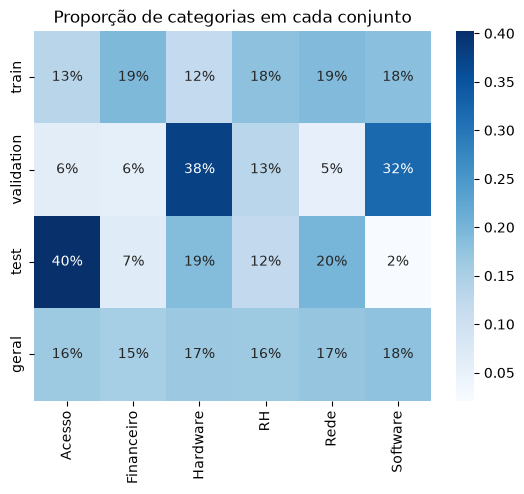

train × validation: 0 imagens e 0 descrições em comum
train × test: 0 imagens e 0 descrições em comum
validation × test: 0 imagens e 0 descrições em comum


In [3]:
resumo = df.groupby("split").agg(chamados=("ticket_id", "size"), imagens=("image_path", "nunique"))
resumo["fração"] = (resumo["chamados"] / len(df)).round(3)
display(resumo.loc[["train", "validation", "test"]])

proporcao = pd.crosstab(df["split"], df["target_category"], normalize="index").loc[["train", "validation", "test"]]
proporcao.loc["geral"] = df["target_category"].value_counts(normalize=True)
proporcao = proporcao.astype(float)
sns.heatmap(proporcao, annot=True, fmt=".0%", cmap="Blues").set(title="Proporção de categorias em cada conjunto", xlabel="", ylabel="")
plt.show()

conjuntos = {p: df[df["split"] == p] for p in ("train", "validation", "test")}
for a, b in (("train", "validation"), ("train", "test"), ("validation", "test")):
    imagens = set(conjuntos[a]["image_path"]) & set(conjuntos[b]["image_path"])
    textos = set(conjuntos[a]["description"]) & set(conjuntos[b]["description"])
    print(f"{a} × {b}: {len(imagens)} imagens e {len(textos)} descrições em comum")

- Não há **nenhuma imagem nem descrição em comum** entre os conjuntos: todo texto do teste é novo para os modelos.
- O preço disso: com só 26 imagens, validação e teste ficaram com **4 imagens cada**, e as proporções se distorceram. A validação é quase toda Hardware e Software, e o teste é 40% Acesso, com só 2% de Software.

Por isso, validação e teste medem coisas diferentes, e o F1 cai de um para o outro (de 0,90 para 0,71 no classificador multimodal). Mesmo assim, preferimos essa divisão: um teste com imagens repetidas do treino daria um número bonito e enganoso.

---
## Parte 1 — O que é cada coluna

### `sentiment_score` — o tom do relato

- Vai de **−1** (negativo) a **+1** (positivo), e **0** é neutro.
- **Substitui** a coluna original do dataset, que não tinha relação com o texto (mostramos isso abaixo).

### As quatro similaridades — que tipo de pedido o texto parece ser

| Coluna | O quanto o chamado se parece com… |
| --- | --- |
| `text_failure_similarity` | uma **falha**: algo quebrado ou indisponível |
| `text_access_request_similarity` | um **pedido de acesso**: conta, senha, permissão |
| `text_guidance_similarity` | uma **dúvida** ou pedido de orientação |
| `text_performance_similarity` | um relato de **lentidão** ou travamento |

- Perto de **1** significa "muito parecido", e perto de **0**, "sem relação". Na prática, os valores ficam entre 0 e 0,75.
- **Não são probabilidades**: as quatro não somam 1, e um chamado pode ser parecido com falha **e** com lentidão ao mesmo tempo.

In [4]:
df.drop_duplicates("title").sample(5, random_state=7)[["title"] + COLUNAS + ["target_category"]].round(2)

,title,sentiment_score,text_failure_similarity,text_access_request_similarity,text_guidance_similarity,text_performance_similarity,target_category
1081,Erro de permissão no Sistema de Notas Fiscais ...,-0.02,0.47,0.49,0.29,0.16,Software
2387,Falha no SAP: superaquece ao tentar importar d...,-0.04,0.23,0.20,0.31,0.36,Software
3106,O usuário não consegue exportar dados devido a...,-0.03,0.48,0.28,0.13,0.14,Acesso
1113,Erro de runtime no SAP durante a abrir documento.,0.05,0.37,0.29,0.27,0.40,Software
1729,O usuário relata tela preta ao tentar acessar ...,0.02,0.31,0.50,0.35,0.50,Acesso


### O que as colunas mostram por categoria

O PLN não usa a categoria para gerar as colunas, mas, se elas mudarem de uma categoria para outra, carregam informação útil para o classificador.

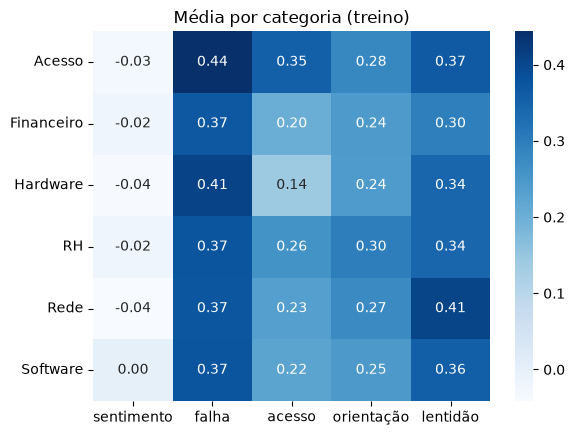

In [5]:
medias = df[df["split"] == "train"].groupby("target_category")[COLUNAS].mean()
medias.columns = ["sentimento", "falha", "acesso", "orientação", "lentidão"]
sns.heatmap(medias, annot=True, fmt=".2f", cmap="Blues").set(title="Média por categoria (treino)", ylabel="")
plt.show()

- **Acesso** é a coluna que mais se destaca: é bem mais alta nos chamados de Acesso.
- **Lentidão** é mais alta em **Rede**.
- **Falha**, **orientação** e **sentimento** variam pouco: quase todo chamado relata um problema, quase nenhum é uma dúvida, e o tom é sempre neutro.

Nenhuma coluna separa as categorias sozinha. O ganho está em somá-las ao texto, à imagem e aos dados tabulares.

### Por que o sentimento quase não varia

O `sentiment_score` original já veio pronto no CSV, e o dataset não explica como ele foi calculado. Guardamos o valor original em `sentiment_audit.parquet` para comparar com o que calculamos.

In [6]:
auditoria = pd.read_parquet(RAIZ / "reports" / "runs" / EXECUCAO / "sentiment_audit.parquet")
treino = df[df["split"] == "train"].merge(auditoria[["ticket_id", "sentiment_score_original"]], on="ticket_id")
treino = treino.rename(columns={"sentiment_score_original": "original", "sentiment_score": "recalculado"})

display(treino.groupby("target_category")[["original", "recalculado"]].agg(["mean", "std"]).round(2))
print("Correlação entre os dois:", round(treino["original"].corr(treino["recalculado"]), 3))
print("Desvio médio entre chamados com o mesmo título → original:",
      round(treino.groupby("title")["original"].std().mean(), 2),
      "| recalculado:", round(treino.groupby("title")["recalculado"].std().mean(), 2))

original       recalculado      
                    mean   std        mean   std
target_category                                 
Acesso              -0.0  0.58       -0.03  0.04
Financeiro         -0.03  0.59       -0.02  0.05
Hardware            -0.0  0.57       -0.04  0.04
RH                  0.01  0.59       -0.02  0.04
Rede               -0.01  0.59       -0.04  0.05
Software            0.03  0.58        0.00  0.04

Correlação entre os dois: 0.006
Desvio médio entre chamados com o mesmo título → original: 0.52 | recalculado: 0.0


- **O original era ruído:** chamados com o mesmo título recebem notas muito diferentes, e a correlação com o texto é nula.
- **O recalculado é coerente, mas o texto é neutro:** textos iguais recebem a mesma nota. Como os chamados são frases curtas e técnicas, sem emoção, os valores ficam todos perto de zero.

---
## Parte 2 — Como as colunas foram geradas

```text
title + description
        │
        ├──► Modelo de inferência textual (NLI) ──► compara com 3 frases de "tom" ───► sentiment_score
        │
        └──► Modelo de embeddings de frases ──────► compara com 12 frases-exemplo ───► 4 similaridades
```

- **Não treinamos nada:** usamos dois modelos multilíngues pré-treinados do Hugging Face, só para inferência.
- **A categoria nunca entra**, para o PLN não "colar" a resposta nas colunas.
- **Tudo fica no YAML** (`src/config/models.yaml`, bloco `modelos.pln`): modelos e frases de referência.

Para mostrar o cálculo, vamos refazer as cinco colunas de um chamado com os modelos salvos na execução (`models/runs/<execução>/pln/`) e comparar com o `enriched.parquet`.

In [7]:
import warnings
warnings.filterwarnings("ignore")
import json, numpy as np, torch
from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

PLN = RAIZ / "models" / "runs" / EXECUCAO / "pln"
config = json.loads((PLN / "metadata.json").read_text(encoding="utf-8"))["config"]

chamado = df[df["ticket_id"] == "4392"].iloc[0]
print("Título:   ", chamado["title"])
print("Descrição:", chamado["description"])

Título:    O usuário não consegue fazer login devido a reinicia sozinho...
Descrição: O usuário não consegue fazer login devido a reinicia sozinho.


### Como o `sentiment_score` é calculado

Usamos o `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli`, um modelo de **NLI** (inferência textual): ele recebe um texto e uma hipótese e diz o quanto o texto **confirma** essa hipótese. Sem treinar nada (*zero-shot*), escrevemos uma hipótese para cada tom:

| Valor | Hipótese |
| --- | --- |
| −1 | "O solicitante expressa insatisfação, frustração ou uma experiência negativa." |
| 0 | "O solicitante apresenta uma informação ou pedido de forma neutra." |
| +1 | "O solicitante expressa satisfação, agradecimento ou uma experiência positiva." |

O modelo dá uma nota de "confirma" para cada hipótese, o softmax transforma as três notas em probabilidades que somam 1, e o sentimento é a média ponderada `p(neg) × (−1) + p(neutro) × 0 + p(pos) × (+1)`.

In [8]:
tok_nli = AutoTokenizer.from_pretrained(PLN / "model")
nli = AutoModelForSequenceClassification.from_pretrained(PLN / "model").eval()
confirma = next(i for i, nome in nli.config.id2label.items() if nome.lower() == "entailment")

texto = chamado["title"] + "\n" + chamado["description"]          # o pipeline junta os dois campos
hipoteses = [c["hypothesis"] for c in config["sentiment"]["candidates"]]
valores = np.array([c["value"] for c in config["sentiment"]["candidates"]])

with torch.inference_mode():
    entrada = tok_nli([texto] * 3, hipoteses, padding=True, truncation="only_first",
                      max_length=config["max_length"], return_tensors="pt")
    notas = nli(**entrada).logits[:, confirma].numpy()            # nota de "confirma" por hipótese

prob = np.exp(notas - notas.max())
prob /= prob.sum()                                                 # softmax: as três somam 1
sentimento = prob @ valores                                        # média ponderada por −1, 0, +1

display(pd.DataFrame({"hipótese": hipoteses, "valor": valores, "nota": notas, "probabilidade": prob}).round(3))
print(f"sentiment_score calculado aqui: {sentimento:.4f} | no enriched.parquet: {chamado['sentiment_score']:.4f}")

,hipótese,valor,nota,probabilidade
0,"O solicitante expressa insatisfação, frustraçã...",-1.0,-2.567,0.080
1,O solicitante apresenta uma informação ou pedi...,0.0,-0.201,0.855
2,"O solicitante expressa satisfação, agradecimen...",1.0,-2.785,0.065


sentiment_score calculado aqui: -0.0157 | no enriched.parquet: -0.0157


A hipótese neutra fica com quase toda a probabilidade, por isso o resultado fica perto de zero, como na maioria dos chamados.

### Como as quatro similaridades são calculadas

Usamos o `paraphrase-multilingual-MiniLM-L12-v2`, que transforma uma frase em um vetor de **384 números** que representa o seu significado. Frases com sentido parecido ficam com vetores parecidos, mesmo usando palavras diferentes.

1. Título e descrição viram vetores separadamente (média dos vetores dos tokens, normalizada para tamanho 1) e são somados com peso igual.
2. Cada uma das 12 frases-exemplo do YAML (três por coluna) também vira um vetor.
3. Calculamos a **similaridade de cosseno** entre o chamado e cada frase-exemplo: 1 = mesmo sentido, 0 = sem relação.
4. Cada coluna fica com o **maior** cosseno do seu grupo.

In [9]:
tok_emb = AutoTokenizer.from_pretrained(PLN / "semantic_model")
emb = AutoModel.from_pretrained(PLN / "semantic_model").eval()
semantic = config["semantic"]

def vetor(frases):
    entrada = tok_emb([" ".join(f.split()) for f in frases], padding=True, truncation=True,
                      max_length=semantic["max_length"], return_tensors="pt")
    with torch.inference_mode():
        tokens = emb(**entrada).last_hidden_state                 # um vetor de 384 números por token
    mascara = entrada["attention_mask"].unsqueeze(-1)
    media = (tokens * mascara).sum(1) / mascara.sum(1)            # média só dos tokens reais
    return torch.nn.functional.normalize(media, dim=1).numpy()     # tamanho 1

v_titulo, v_descricao = vetor([chamado["title"], chamado["description"]])
v_chamado = v_titulo + v_descricao                                 # peso igual para os dois campos
v_chamado /= np.linalg.norm(v_chamado)

print("Tamanho do vetor:", v_chamado.shape[0])
print("Primeiros 8 números:", v_chamado[:8].round(3))
print("Cosseno entre título e descrição:", round(float(v_titulo @ v_descricao), 3))

Tamanho do vetor: 384
Primeiros 8 números: [-0.017 -0.074  0.029  0.033 -0.03  -0.051  0.021  0.067]
Cosseno entre título e descrição: 0.979


Como os vetores têm tamanho 1, o produto `@` entre eles já é o cosseno. Agora comparamos o chamado com as 12 frases-exemplo:

In [10]:
linhas = []
for coluna, exemplos in semantic["prototypes"].items():
    cossenos = vetor(exemplos) @ v_chamado
    linhas += [{"coluna": coluna, "frase-exemplo": f, "cosseno": c} for f, c in zip(exemplos, cossenos)]
tabela = pd.DataFrame(linhas)
display(tabela.round(3))

resumo = tabela.groupby("coluna", sort=False)["cosseno"].max().to_frame("calculado aqui (maior cosseno)")
resumo["no enriched.parquet"] = [chamado[c] for c in resumo.index]
resumo.round(4)

,coluna,frase-exemplo,cosseno
0,text_failure_similarity,O sistema apresenta um erro e não funciona.,0.360
1,text_failure_similarity,O equipamento parou de funcionar e preciso de ...,0.236
2,text_failure_similarity,Não consigo realizar minha atividade porque o ...,0.345
3,text_access_request_similarity,Solicito criação de uma conta e liberação de a...,0.325
4,text_access_request_similarity,Preciso de permissão para utilizar o sistema.,0.339
5,text_access_request_similarity,Quero redefinir minha senha para acessar minha...,0.532
6,text_guidance_similarity,Tenho uma dúvida e preciso de orientação para ...,0.113
7,text_guidance_similarity,Gostaria de saber como realizar esta operação.,0.031
8,text_guidance_similarity,Solicito informações e instruções sobre o serv...,0.064
9,text_performance_similarity,O sistema está lento e demora muito para respo...,0.106


,calculado aqui (maior cosseno),no enriched.parquet
coluna,,
text_failure_similarity,0.3601,0.3601
text_access_request_similarity,0.5323,0.5323
text_guidance_similarity,0.1130,0.1130
text_performance_similarity,0.1608,0.1608


O valor mais alto é o de **acesso**, puxado por "Quero redefinir minha senha para acessar minha conta.", a frase mais próxima de "não consegue fazer login". Os valores batem com os do `enriched.parquet`.

### O mesmo cálculo para todos os chamados

No pipeline, esse cálculo é feito pela classe `SemanticNLP` (`src/models/language.py`). Abaixo, rodamos essa classe com os modelos salvos nos 5000 chamados e comparamos com o `enriched.parquet`.

In [11]:
import sys
sys.path.insert(0, str(RAIZ))
from src.models.language import SemanticNLP

pln = SemanticNLP.restore(PLN, config, RAIZ)
novas = pln.transform(df[["title", "description"]])

display(novas.head().round(3))
print("Maior diferença em relação ao enriched.parquet:")
print((novas - df[novas.columns]).abs().max().apply(lambda d: f"{d:.1e}").to_string())

,sentiment_score,text_failure_similarity,text_access_request_similarity,text_guidance_similarity,text_performance_similarity
0,-0.087,0.402,0.192,0.295,0.240
1,-0.039,0.300,0.307,0.385,0.362
2,-0.025,0.223,0.111,0.237,0.197
3,0.035,0.440,0.225,0.271,0.512
4,-0.055,0.576,0.333,0.255,0.365


Maior diferença em relação ao enriched.parquet:
sentiment_score                   4.0e-07
text_failure_similarity           1.2e-07
text_access_request_similarity    8.9e-08
text_guidance_similarity          8.9e-08
text_performance_similarity       6.0e-08


As diferenças são só de arredondamento: as colunas do dataset são exatamente o resultado desse código.

| Arquivo → função | O que faz |
| --- | --- |
| `features_pipeline.py` → `run_features` | Roda as etapas do YAML e junta as colunas ao dataset |
| `language.py` → `SemanticNLP.fit` | Carrega os modelos e vetoriza as frases-exemplo (não aprende nada) |
| `language.py` → `SemanticNLP.transform` | Gera as cinco colunas para treino, validação e teste |
| `semantic_text.py` → `intent_similarities` | Cosseno com as frases-exemplo e o maior valor de cada grupo |

---
## Parte 3 — O que os dados revelam

As análises abaixo usam o **treino**, exceto quando medimos desempenho.

### 1. Os textos são montados a partir de frases-modelo

Os chamados parecem variados, mas combinam poucas peças: um começo fixo, um sistema ou equipamento e um sintoma.

In [12]:
from sklearn.feature_extraction.text import CountVectorizer

treino = df[df["split"] == "train"]
print("Palavras diferentes em todas as descrições:", len(set(" ".join(df["description"]).lower().split())))
print("Descrições diferentes:", df["description"].nunique(), "de", len(df), "chamados")
print("Títulos que são a descrição cortada com '...':", f"{df['title'].str.endswith('...').mean():.0%}")
display(df["description"].str.split().str[:3].str.join(" ").value_counts().head(6).to_frame("chamados"))

Palavras diferentes em todas as descrições: 194
Descrições diferentes: 2564 de 5000 chamados
Títulos que são a descrição cortada com '...': 25%


,chamados
description,
O usuário não,331
Falha no sistema,302
O sistema de,268
O acesso à,191
Problema de hardware:,183
O usuário relatou,181


O vocabulário inteiro tem menos de 200 palavras. Isso confirma que o dataset é sintético e explica por que as colunas do PLN variam pouco.

### 2. Até palavras comuns denunciam a categoria

Para cada categoria, buscamos as palavras que aparecem em boa parte dos seus chamados e quase nunca nas outras:

In [13]:
cv = CountVectorizer(min_df=20)
X = cv.fit_transform(treino["description"].astype(str)) > 0
palavras = cv.get_feature_names_out()
y = treino["target_category"].astype(str).to_numpy()

linhas = []
for cat in sorted(set(y)):
    dentro, fora = X[y == cat].mean(0).A1, X[y != cat].mean(0).A1
    for i in (dentro / (fora + 0.01)).argsort()[::-1][:5]:
        linhas.append({"categoria": cat, "palavra": palavras[i], "nos chamados dela": f"{dentro[i]:.0%}", "nas outras": f"{fora[i]:.0%}"})
pd.DataFrame(linhas).set_index(["categoria", "palavra"])

nos chamados dela nas outras
categoria  palavra                                   
Acesso     relata                      36%         0%
           por                         36%         0%
           bloqueado                   36%         0%
           usuário                     64%         7%
           acesso                      36%         4%
Financeiro financeiro                  58%         0%
           módulo                      27%         0%
           corretamente                21%         0%
           tesouraria                   8%         0%
           contabilidade                7%         0%
Hardware   placa                       32%         0%
           hardware                    25%         0%
           relatou                     21%         0%
           que                         21%         0%
           responde                    20%         0%
RH         para                        19%         0%
           rh                          30%         3%
           folha                       14%         2%
           recrutamento                14%         3%
           portal                      12%         2%
Rede       rede                        66%         1%
           conectividade               20%         0%
           instável                    20%         0%
           conexão                     23%         1%
           internet                    10%         0%
Software   quando                      20%         0%
           aplicativo                  20%         0%
           fecha                       20%         0%
           word                        15%         0%
           excel                       13%         0%

Além das esperadas ("rede", "financeiro"), palavras sem significado próprio, como **"por"**, **"que"**, **"quando"** e **"para"**, aparecem em uma única categoria, porque fazem parte da frase-modelo dela. É por isso que o TF-IDF do classificador funciona tão bem: ele reconhece a **frase-modelo**, não necessariamente o problema.

### 3. O mesmo texto às vezes aparece com categorias diferentes

In [14]:
por_texto = df.groupby("description")["target_category"].nunique()
ambiguos = por_texto[por_texto > 1].index
print("Descrições com mais de uma categoria:", len(ambiguos), "| chamados afetados:", df["description"].isin(ambiguos).sum())

acerto_maximo = df.groupby("description")["target_category"].agg(lambda s: s.value_counts().iloc[0]).sum() / len(df)
print(f"Acerto máximo possível olhando só a descrição: {acerto_maximo:.1%}")
df[df["description"].isin(ambiguos[:3])].groupby(["description", "target_category"]).size().unstack(fill_value=0)

Descrições com mais de uma categoria: 65 | chamados afetados: 280


Acerto máximo possível olhando só a descrição: 98.0%


target_category,Acesso,RH
description,,
O usuário não consegue abrir documento devido a apresenta erro.,3,1
O usuário não consegue abrir documento devido a congela.,2,2
O usuário não consegue abrir documento devido a desliga.,1,2


Nesses casos, nenhum modelo de texto acerta sempre. Mas é pouco: olhando só a descrição, o acerto máximo possível fica em **98%**.

### 4. As intenções do PLN não coincidem com as categorias

Para cada chamado, vemos com qual dos quatro tipos de pedido ele mais se parece:

,fração dos chamados
falha,0.53
lentidão,0.35
acesso,0.06
orientação,0.05


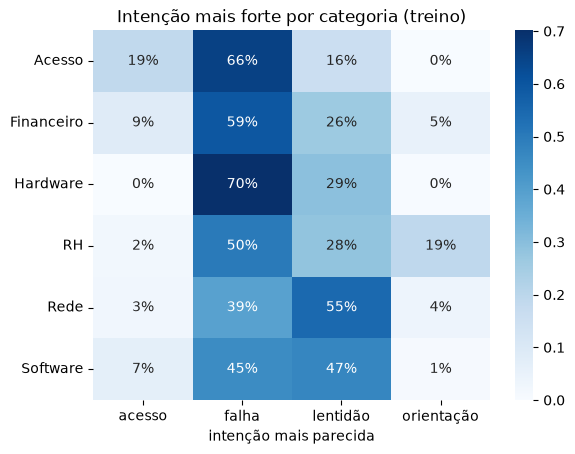

In [15]:
intencao = (treino[COLUNAS[1:]].idxmax(axis=1)
            .map({"text_failure_similarity": "falha", "text_access_request_similarity": "acesso",
                  "text_guidance_similarity": "orientação", "text_performance_similarity": "lentidão"}))
display(intencao.value_counts(normalize=True).round(2).to_frame("fração dos chamados"))
sns.heatmap(pd.crosstab(treino["target_category"], intencao, normalize="index"), annot=True, fmt=".0%", cmap="Blues") \
   .set(title="Intenção mais forte por categoria (treino)", xlabel="intenção mais parecida", ylabel="")
plt.show()

- **Falha** vence em cerca de metade dos chamados e é forte em todas as categorias (de 39% em Rede a 70% em Hardware).
- **Lentidão** vence na maioria dos chamados de Rede e em quase metade dos de Software.
- Mesmo em **Acesso**, "acesso" vence em menos de 1 a cada 5 chamados: os textos falam de erro e bloqueio, não de pedido de senha.

As similaridades medem o **tipo de pedido**, que é diferente da **categoria**. Por isso complementam o texto, mas não o substituem.

### 5. Quanto o PLN sabe sobre a categoria

Comparamos uma regressão logística treinada **só com as cinco colunas** com a mesma regressão lendo o texto inteiro por TF-IDF:

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score

partes = {p: df[df["split"] == p] for p in ("train", "validation", "test")}
texto = lambda d: d["title"] + " " + d["description"]

so_pln = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(partes["train"][COLUNAS], partes["train"]["target_category"])
tfidf = make_pipeline(TfidfVectorizer(ngram_range=(1, 2)), LogisticRegression(max_iter=2000)).fit(texto(partes["train"]), partes["train"]["target_category"])

pd.DataFrame({
    "chute aleatório": {p: 1 / 6 for p in ("validation", "test")},
    "só as 5 colunas do PLN": {p: f1_score(partes[p]["target_category"], so_pln.predict(partes[p][COLUNAS]), average="macro") for p in ("validation", "test")},
    "texto inteiro (TF-IDF)": {p: f1_score(partes[p]["target_category"], tfidf.predict(texto(partes[p])), average="macro") for p in ("validation", "test")},
}).T.round(2).rename(columns={"validation": "F1 validação", "test": "F1 teste"})

,F1 validação,F1 teste
chute aleatório,0.17,0.17
só as 5 colunas do PLN,0.33,0.35
texto inteiro (TF-IDF),0.86,0.68


Só com as cinco colunas, o F1 fica em torno de **0,33**, o dobro de um chute aleatório. O PLN carrega informação real, mas bem menos que o texto completo, porque resume cada chamado em cinco números, enquanto o TF-IDF enxerga cada palavra e reconhece as frases-modelo. A queda do TF-IDF no teste vem da divisão por imagem, explicada no início.

### Limitações

- **As colunas dependem das frases que escolhemos no YAML.** Trocar as frases-exemplo muda os valores.
- **As similaridades medem a estrutura da frase, não o assunto.** "Erro de permissão no Sistema ERP" tem alta similaridade de acesso, mesmo sendo Software.
- **Os valores não são probabilidades calibradas.**
- **O dataset é sintético.** Em chamados reais, mais longos e variados, o comportamento pode ser diferente.